# Walkthrough: how much does the surface of a reference reveal?
Run `bash scripts/fetch_data.sh` first. Every number below is computed live from `data/raw/` or read from `results/tables/`.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import pandas as pd, numpy as np
from citesurf.data import load_split, equalise
from citesurf.features import featurise, render, completeness
print('ROOT =', ROOT.name)

ROOT = ATR_Lab02_MCL2026011_CitationSurface


## 1. The data a detector is allowed to see

In [2]:
dev, test, ww = load_split('dev_public'), load_split('test_public'), load_split('supplement_chatgpt_citations')
for n, s in [('dev', dev), ('test', test), ('W&W', ww)]:
    print(f'{n:5s} n={len(s):4d}  hallucinated={sum(r.y for r in s):4d}  valid={sum(1-r.y for r in s):4d}')
r = test[0]
print('\nvisible keys:', list(r.entry))
print('rendered   :', render(r.entry))
print('label      :', r.y, r.htype)

dev   n=1119  hallucinated= 615  valid= 504
test  n= 831  hallucinated= 524  valid= 307
W&W   n= 341  hallucinated= 169  valid= 172

visible keys: ['bibtex_type', 'fields']
rendered   : Zitao Liu and Qiongqiong Liu and Jiahao Chen and Shuyan Huang and Weiqi Luo. 2031. simpleKT: A Simple But Tough-to-Beat Baseline for Knowledge Tracing. ICLR
label      : 1 future_date


## 2. One real and one fabricated ChatGPT citation (W&W): same fields, same format

In [3]:
real = next(x for x in ww if x.y == 0); fake = next(x for x in ww if x.y == 1)
for x in (real, fake):
    print(x.y, '|', render(x.entry), '| completeness', completeness(x.entry))

0 | R. F. Baumeister and M. R. Leary. 1995. The need to belong: Desire for interpersonal attachments as a fundamental human motivation. Psychological bulletin | completeness 4
1 | M. Jockers and D. Witten. 2010. A computational approach to theme in the novel. Literary and Linguistic Computing | completeness 4


## 3. Surface features for one entry (extended set M1)

In [4]:
X, names = featurise([test[0].entry], ['hallmark','author_style','title_style','id_consistency'])
print(len(names), 'features'); print(dict(list(zip(names, X[0].round(2)))[:12]))

50 features
{'arxiv_before_publication_violated': np.float64(0.0), 'arxiv_year_gap': np.float64(0.0), 'auth_any_digit': np.float64(0.0), 'auth_any_nonascii': np.float64(0.0), 'auth_dup_surname': np.float64(1.0), 'auth_frac_full_given': np.float64(1.0), 'auth_frac_hyphen': np.float64(0.0), 'auth_frac_initials': np.float64(0.0), 'auth_max_surname_len': np.float64(5.0), 'auth_mean_surname_len': np.float64(3.6), 'auth_missing': np.float64(0.0), 'author_chars': np.float64(75.0)}


## 4. Main results (from `results/tables/main_summary.csv`)

In [5]:
s = pd.read_csv(ROOT / 'results/tables/main_summary.csv')
keep = ['test_public[full-trained,full-scored]','test_public[eq-trained,eq-scored]','ww_transfer[full-trained]','ww_groupcv']
t = s[s.eval_set.isin(keep) & (s.model != 'B0_majority')].pivot(index='model', columns='eval_set', values='auroc_mean')[keep]
print(t.round(3).to_string())

eval_set              test_public[full-trained,full-scored]  test_public[eq-trained,eq-scored]  ww_transfer[full-trained]  ww_groupcv
model                                                                                                                                
B1_completeness_rule                                  0.515                              0.512                      0.500       0.500
B2_hallmark_gbm                                       0.764                              0.721                      0.546       0.592
M1_extended_gbm                                       0.797                              0.748                      0.549       0.679
M2_charngram_lr                                       0.788                              0.746                      0.525       0.629


In [6]:
print(pd.read_csv(ROOT / 'results/tables/reference_points.csv')[['reference','eval_set','auroc','used_lookups']].round(3).to_string(index=False))

                                               reference    eval_set  auroc  used_lookups
                              llm_openrouter_deepseek_r1 test_public  0.778         False
                              llm_openrouter_deepseek_v3 test_public  0.589         False
                             llm_openrouter_gemini_flash test_public  0.738         False
                               llm_openrouter_gemini_pro test_public  0.720         False
                         llm_openrouter_llama_4_maverick test_public  0.750         False
                                  llm_openrouter_mistral test_public  0.716         False
                                 llm_openrouter_qwen_max test_public  0.677         False
                                     llm_openrouter_qwen test_public  0.661         False
bibtex-updater 1.4.0 (database lookup; HALLMARK release)          ww  0.957          True


## 5. Figure: AUROC across conditions

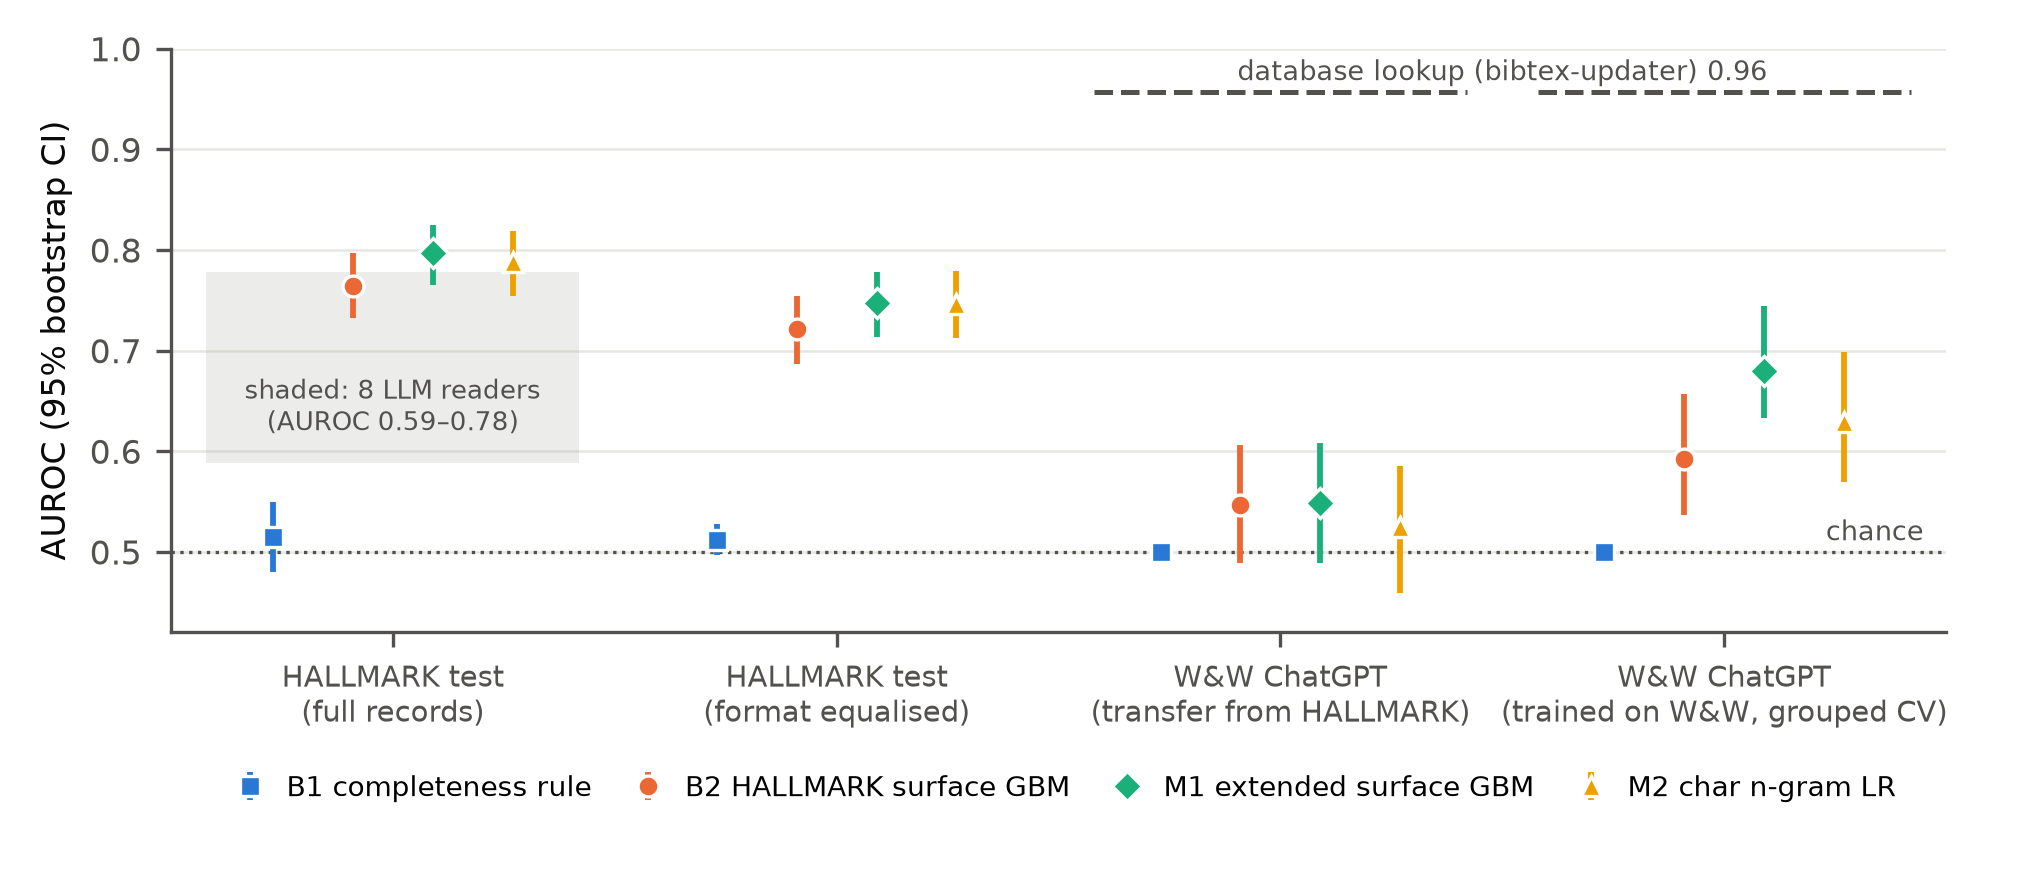

In [7]:
from IPython.display import Image
Image(filename=str(ROOT / 'results/figures/fig_auroc_overview.png'))

## 6. Quick rerun of one component (for the viva): M1 on test_public, seed 0

In [8]:
from citesurf.models import build
from citesurf.metrics import auroc
import numpy as np
m = build('M1_extended_gbm', 0).fit([r.entry for r in dev], np.array([r.y for r in dev]))
print('M1 test AUROC (live):', round(auroc(np.array([r.y for r in test]), m.score([r.entry for r in test])), 3))

M1 test AUROC (live): 0.797
